# Assignment 04

**Name: 肖文赜**

**SUSTech ID: 12631523**

# 1. Global Earthquakes

In this problem set, we will use [this file](https://zhu-group.github.io/ese5023/download/usgs_earthquakes.csv) from the USGS Earthquakes Database. The dataset is similar to the one you use in [Assignment 02](https://zhu-group.github.io/ese5023/Assignment_02.html#1_Significant_earthquakes_since_2150_BC). Use the file provided (`usgs_earthquakes.csv`) to recreate the following map. Use the `mag` column for magnitude. **[10 points]**

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

#按照图片要求筛选 2014 年，再按mag取前 50 条
earthquakes = pd.read_csv('usgs_earthquakes.csv')
earthquakes['time'] = pd.to_datetime(earthquakes['time'])
earthquakes_2014 = earthquakes.loc[earthquakes['time'].dt.year == 2014]
earthquakes_2014 = earthquakes_2014.dropna(subset=['latitude', 'longitude', 'mag'])



earthquakes_sorted = earthquakes_2014.sort_values('mag', ascending=False, kind='stable')
earthquakes_sorted = earthquakes_sorted.reset_index(drop=True)
top50 = earthquakes_sorted.loc[:49]
##看一下结果
print(top50[['time', 'place', 'mag']].head())

                     time                                    place  mag
0 2014-04-01 23:46:47.260                94km NW of Iquique, Chile  8.2
1 2014-06-23 20:53:09.700  19km SE of Little Sitkin Island, Alaska  7.9
2 2014-04-03 02:43:13.110                53km SW of Iquique, Chile  7.7
3 2014-04-12 20:14:39.300    93km SSE of Kirakira, Solomon Islands  7.6
4 2014-04-19 13:28:00.810     70km SW of Panguna, Papua New Guinea  7.5


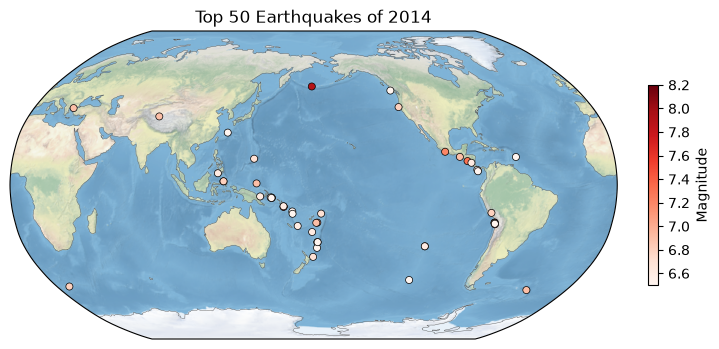

In [10]:
fig = plt.figure(figsize=(10, 4))
# 按反馈把中央经线设为 180°，让太平洋位于图中央
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
##地图上色
ax.stock_img()
ax.coastlines(resolution='110m', color='0.35', linewidth=0.3)

points = ax.scatter(
    top50['longitude'], top50['latitude'], c=top50['mag'],
    cmap='Reds', s=26, edgecolors='black', linewidths=0.5,
    transform=ccrs.PlateCarree(), zorder=9999
)
colorbar = fig.colorbar(points, ax=ax, pad=0.04, shrink=0.65)
colorbar.set_ticks([6.6, 6.8, 7.0, 7.2, 7.4, 7.6, 7.8, 8.0, 8.2])
colorbar.set_label('Magnitude')
ax.set_title('Top 50 Earthquakes of 2014')
plt.show()

---

# 2. Explore a `netCDF` dataset

Browse the NASA’s Goddard Earth Sciences Data and Information Services Center (GES DISC) [website](https://disc.gsfc.nasa.gov/). Search and download a dataset you are interested in. You are also welcome to use data from your group in this problem set. But the dataset should be in `netCDF` format. For this problem set, you are welcome to use the same dataset you used in [Assignment 03](https://zhu-group.github.io/ese5023/Assignment_03.html#3_Explore_a_netCDF_dataset).

**2.1 [10 points]** Make a global map of a certain variable. Your figure should contain: a project, x label and ticks, y label and ticks, title, gridlines, legend, colorbar, masks or features, annotations, and text box (**1 point each**).

In [ ]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import matplotlib.ticker as mticker

gpcp = xr.open_dataset('GPCPDAY_2015_2019_processed.nc')

# 直接选取2015年1月的全球月平均降水率
precip = gpcp['precip_monthly']
jan_rain = precip.sel(month_time='2015-01-01')

print('降水最大值：' + format(float(jan_rain.max()), '.2f') + ' mm/day')

#取最大值格点的具体位置
global_row, global_col = np.unravel_index(np.nanargmax(jan_rain.values), jan_rain.shape)
global_lon = float(jan_rain['lon'][global_col])
global_lat = float(jan_rain['lat'][global_row])

print('最大值位置（经度，纬度）：', global_lon, global_lat)

降水最大值：38.08 mm/day
最大值位置（经度，纬度）： 150.25 -4.75


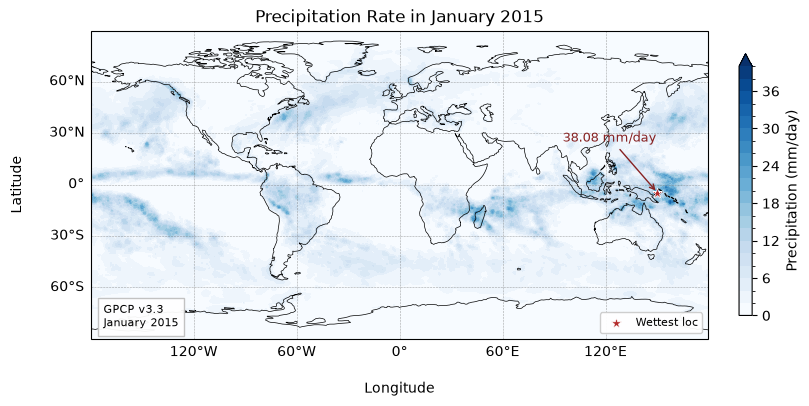

In [ ]:
geo = ccrs.PlateCarree()
fig = plt.figure(figsize=(10, 4))
ax = plt.axes(projection=geo)

rain_map = jan_rain.plot.contourf(
    ax=ax, transform=geo, cmap='Blues', levels=np.linspace(0, 40, 21),
    extend='max', add_colorbar=False
)
ax.coastlines(resolution='110m', linewidth=0.5)
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
gl = ax.gridlines(crs=geo, draw_labels=True, linewidth=0.4,
                  linestyle='--', color='0.45', alpha=0.65)
gl.xlocator = mticker.FixedLocator(range(-180, 181, 60))
gl.ylocator = mticker.FixedLocator(range(-90, 91, 30))
gl.top_labels = False
gl.right_labels = False
ax.text(0.5, -0.14, 'Longitude', transform=ax.transAxes, ha='center', va='top')
ax.text(-0.12, 0.5, 'Latitude', transform=ax.transAxes, ha='center', va='center', rotation=90)

ax.scatter(global_lon, global_lat, transform=geo, marker='*', s=62,
           color='#b42c2c', edgecolors='white', linewidths=0.5, zorder=5,
           label='Wettest loc')
ax.annotate(format(float(jan_rain.max()), '.2f') + ' mm/day',
            xy=(global_lon, global_lat), xytext=(95, 25),
            arrowprops={'arrowstyle': '->', 'color': '#872222'},
            color='#872222', fontsize=9, zorder=6)
ax.text(0.02, 0.04, 'GPCP v3.3\nJanuary 2015', transform=ax.transAxes,
        fontsize=8, bbox={'facecolor': 'white', 'edgecolor': '0.75', 'alpha': 0.95})
ax.legend(loc='lower right', fontsize=8, framealpha=0.95)
fig.colorbar(rain_map, ax=ax, pad=0.04, shrink=0.85, label='Precipitation (mm/day)')
ax.set_title('Precipitation Rate in January 2015')
plt.show()

**2.2 [10 points]** Make a regional map of the same variable. Your figure should contain: a different project, x label and ticks, y label and ticks, title, gridlines, legend, colorbar, masks or features, annotations, and text box (**1 point each**).

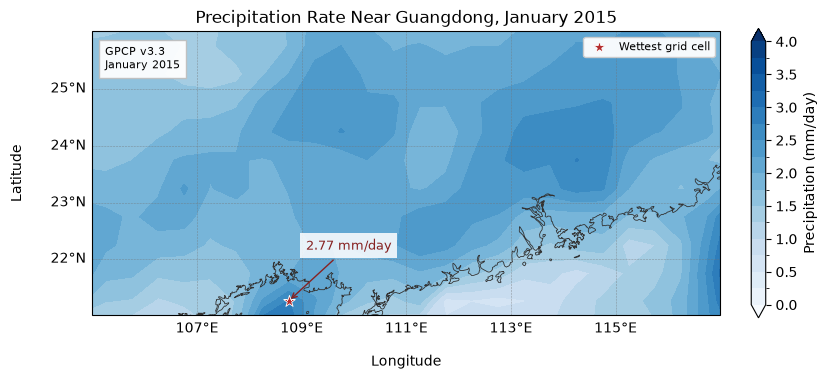

In [ ]:
#纬度从北往南排列
region_rain = jan_rain.sel(lat=slice(26, 21), lon=slice(105, 117))

#绘图多取一圈网格
plot_rain = jan_rain.sel(lat=slice(26.5, 20.5), lon=slice(104.5, 117.5))

#选择局部区域21–26、105–117
fig = plt.figure(figsize=(10, 4))
ax = plt.axes(projection=ccrs.Mercator())
ax.set_extent([105, 117, 21, 26], crs=geo)

rain_map = plot_rain.plot.contourf(
    ax=ax, transform=geo, cmap='Blues', levels=np.linspace(0, 4, 17),
    extend='both', add_colorbar=False
)
ax.coastlines(resolution='10m', color='0.2', linewidth=0.6)
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
gl = ax.gridlines(crs=geo, draw_labels=True, linewidth=0.4,
                  linestyle='--', color='0.45', alpha=0.65)
gl.xlocator = mticker.FixedLocator(range(105, 118, 2))
gl.ylocator = mticker.FixedLocator(range(21, 27))
gl.top_labels = False
gl.right_labels = False
ax.text(0.5, -0.14, 'Longitude', transform=ax.transAxes, ha='center', va='top')
ax.text(-0.12, 0.5, 'Latitude', transform=ax.transAxes, ha='center', va='center', rotation=90)
##区域最大值
region_row, region_col = np.unravel_index(np.nanargmax(region_rain.values), region_rain.shape)
region_lon = float(region_rain['lon'][region_col])
region_lat = float(region_rain['lat'][region_row])

ax.scatter(region_lon, region_lat, transform=geo, marker='*', s=78,
           color='#b42c2c', edgecolors='white', linewidths=0.6, zorder=5,
           label='Wettest grid cell')
ax.annotate(f'{float(region_rain.max()):.2f} mm/day',
            xy=(region_lon, region_lat), transform=geo,
            xytext=(0.34, 0.23), textcoords='axes fraction',
            arrowprops={'arrowstyle': '->', 'color': '#872222'},
            color='#872222', fontsize=9, zorder=6,
            bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.85})
ax.text(0.02, 0.95, 'GPCP v3.3\nJanuary 2015', transform=ax.transAxes, va='top',
        fontsize=8, bbox={'facecolor': 'white', 'edgecolor': '0.75', 'alpha': 0.95})
ax.legend(loc='upper right', fontsize=8, framealpha=0.95)
fig.colorbar(rain_map, ax=ax, pad=0.04, shrink=0.94, label='Precipitation (mm/day)')
ax.set_title('Precipitation Rate Near Guangdong, January 2015')
plt.show()